# 1. Import Libraries & Load Dataset

In [2]:
import numpy as np
import pandas as pd

from sklearn.datasets import load_wine
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans

from sklearn.metrics import (
    silhouette_score,
    davies_bouldin_score,
    calinski_harabasz_score
)

# Load dataset without using target labels
wine = load_wine()

X = pd.DataFrame(
    wine.data,
    columns=wine.feature_names
)

print("Dataset shape:", X.shape)
print("\nFirst 5 observations:")
print(X.iloc[:5, :6].round(2).to_string(index=False))


Dataset shape: (178, 13)

First 5 observations:
 alcohol  malic_acid  ash  alcalinity_of_ash  magnesium  total_phenols
   14.23        1.71 2.43               15.6      127.0           2.80
   13.20        1.78 2.14               11.2      100.0           2.65
   13.16        2.36 2.67               18.6      101.0           2.80
   14.37        1.95 2.50               16.8      113.0           3.85
   13.24        2.59 2.87               21.0      118.0           2.80


# Data Quality & EDA

In [3]:
# Missing values
print("Missing values:", X.isna().sum().sum())

# Duplicate observations
print("Duplicate rows:", X.duplicated().sum())

# Descriptive statistics
selected_features = [
    "alcohol",
    "malic_acid",
    "color_intensity",
    "proline"
]

print(
    X[selected_features]
    .describe()
    .loc[["mean", "std", "min", "max"]]
    .round(2)
)


Missing values: 0
Duplicate rows: 0
      alcohol  malic_acid  color_intensity  proline
mean    13.00        2.34             5.06   746.89
std      0.81        1.12             2.32   314.91
min     11.03        0.74             1.28   278.00
max     14.83        5.80            13.00  1680.00


# Outlier Detection - IQR Method

In [4]:
Q1 = X.quantile(0.25)
Q3 = X.quantile(0.75)

IQR = Q3 - Q1

lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR

outlier_mask = (
    (X < lower_bound) |
    (X > upper_bound)
).any(axis=1)

print("Outlier observations:", outlier_mask.sum())


Outlier observations: 17


# Feature Scaling

In [5]:
scaler = StandardScaler()

X_scaled = scaler.fit_transform(X)

print("Scaled dataset shape:", X_scaled.shape)
print("Mean (first feature):",round(X_scaled[:, 0].mean(), 6))
print("Std (first feature):",round(X_scaled[:, 0].std(), 6))


Scaled dataset shape: (178, 13)
Mean (first feature): 0.0
Std (first feature): 1.0


# K-Means Clustering & Optimal K

In [6]:

results = []

for k in range(2, 7):
    model = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=20
    )

    labels = model.fit_predict(X_scaled)

    results.append({
        "k": k,
        "Silhouette": round(
            silhouette_score(X_scaled, labels), 3
        ),
        "DBI": round(
            davies_bouldin_score(X_scaled, labels), 3
        ),
        "CH": round(
            calinski_harabasz_score(X_scaled, labels), 1
        )
    })

results_df = pd.DataFrame(results)

print(results_df.to_string(index=False))

 k  Silhouette   DBI   CH
 2       0.259 1.526 69.5
 3       0.285 1.389 70.9
 4       0.259 1.817 56.2
 5       0.232 1.681 47.2
 6       0.237 1.554 41.7


# Final K-Means Model

In [7]:
best_k = int(
    results_df.loc[
        results_df["Silhouette"].idxmax(), "k"
    ]
)

final_model = KMeans(
    n_clusters=best_k,
    random_state=42,
    n_init=20
)

cluster_labels = final_model.fit_predict(X_scaled)

print("Optimal K:", best_k)

print("\nCluster sizes:")
print(
    pd.Series(cluster_labels)
    .value_counts()
    .sort_index()
    .to_string()
)

Optimal K: 3

Cluster sizes:
0    65
1    51
2    62


## 2D Cluster Visualization via PCA

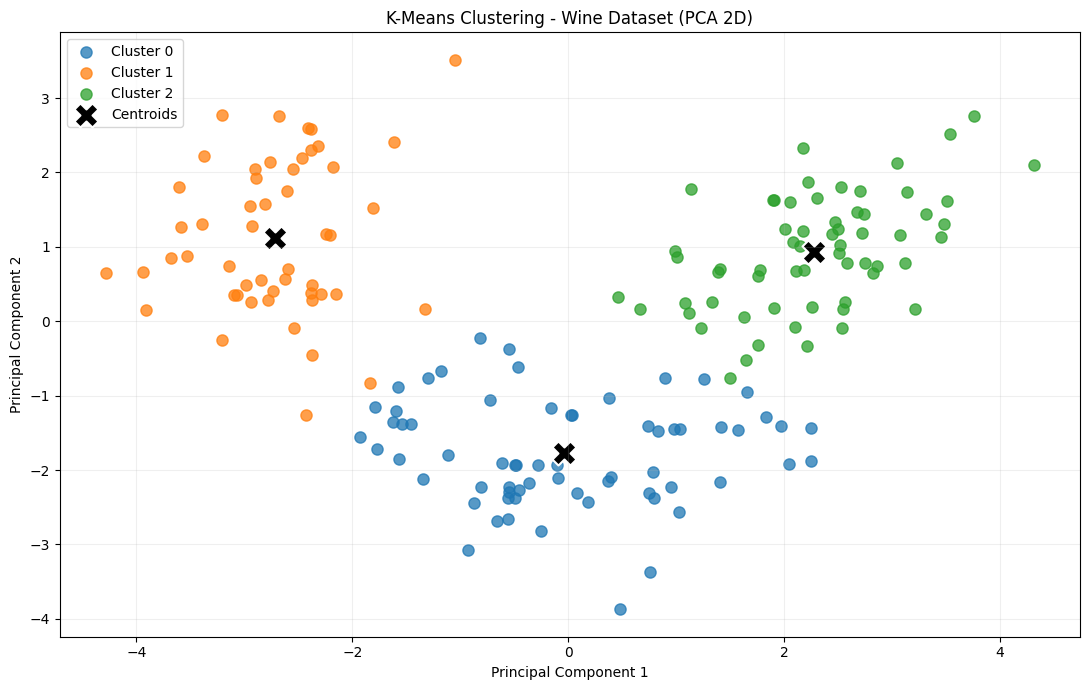

PC1 Explained Variance: 36.20%
PC2 Explained Variance: 19.21%
Total Explained Variance: 55.41%


In [17]:
import matplotlib.pyplot as plt
from sklearn.decomposition import PCA

# Reduce the scaled data to two dimensions
pca = PCA(n_components=2)
X_pca = pca.fit_transform(X_scaled)

# Project K-Means centroids into PCA space
centroids_pca = pca.transform(
    final_model.cluster_centers_
)

# Create visualization
plt.figure(figsize=(11, 7))

for cluster_id in np.unique(cluster_labels):
    mask = cluster_labels == cluster_id

    plt.scatter(
        X_pca[mask, 0],
        X_pca[mask, 1],
        s=65,
        alpha=0.75,
        label=f"Cluster {cluster_id}"
    )

# Visualize cluster centroids
plt.scatter(
    centroids_pca[:, 0],
    centroids_pca[:, 1],
    c="black",
    marker="X",
    s=300,
    edgecolors="white",
    linewidths=1.5,
    label="Centroids"
)

plt.xlabel("Principal Component 1")
plt.ylabel("Principal Component 2")
plt.title("K-Means Clustering - Wine Dataset (PCA 2D)")

plt.legend()
plt.grid(alpha=0.2)
plt.tight_layout()
plt.show()

# Explained variance
print("PC1 Explained Variance:",f"{pca.explained_variance_ratio_[0]:.2%}")

print("PC2 Explained Variance:",f"{pca.explained_variance_ratio_[1]:.2%}")

print("Total Explained Variance:",f"{pca.explained_variance_ratio_.sum():.2%}")

## Silhouette Analysis

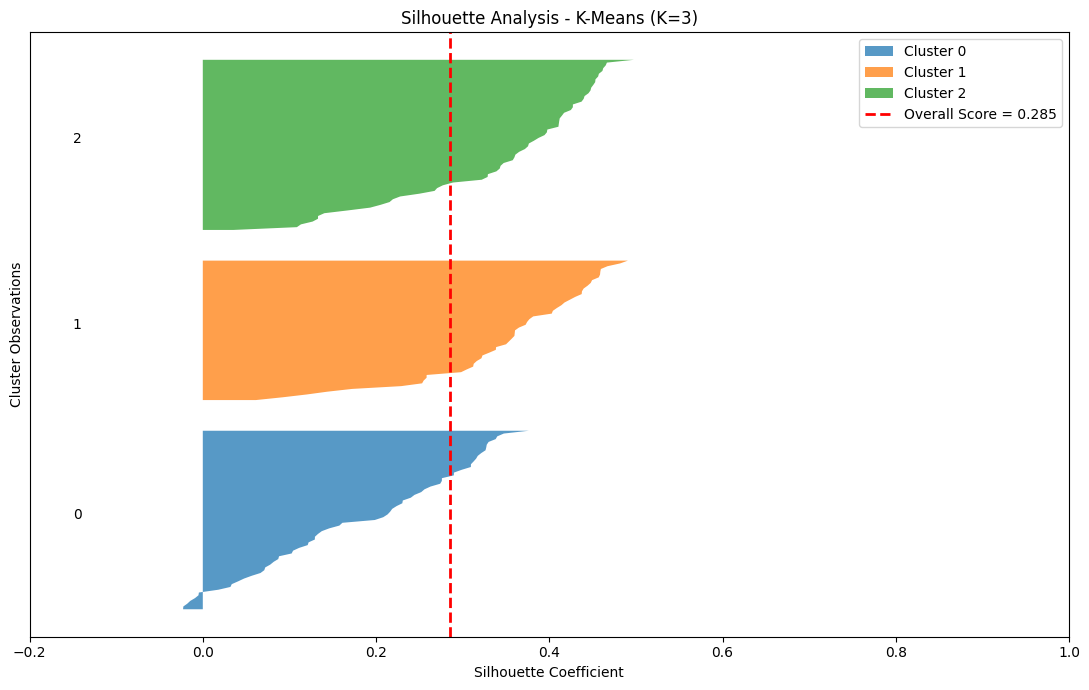

Overall Silhouette Score: 0.285

Cluster-level Summary:
         observations  mean_silhouette  min_silhouette  negative_samples
cluster                                                                 
0                  65            0.177          -0.023                 7
1                  51            0.351           0.061                 0
2                  62            0.343           0.035                 0


In [18]:
from sklearn.metrics import (
    silhouette_samples,
    silhouette_score
)

# Calculate silhouette score for each observation
sample_scores = silhouette_samples(
    X_scaled,
    cluster_labels
)

# Calculate overall silhouette score
overall_score = silhouette_score(
    X_scaled,
    cluster_labels
)

# Create silhouette analysis figure
fig, ax = plt.subplots(figsize=(11, 7))

y_lower = 10

for cluster_id in np.unique(cluster_labels):

    # Select scores belonging to this cluster
    cluster_scores = sample_scores[
        cluster_labels == cluster_id
    ]

    # Sort scores
    cluster_scores.sort()

    cluster_size = len(cluster_scores)
    y_upper = y_lower + cluster_size

    # Plot silhouette distribution
    ax.fill_betweenx(
        np.arange(y_lower, y_upper),
        0,
        cluster_scores,
        alpha=0.75,
        label=f"Cluster {cluster_id}"
    )

    # Add cluster label
    ax.text(
        -0.15,
        y_lower + 0.5 * cluster_size,
        str(cluster_id)
    )

    y_lower = y_upper + 10

# Overall silhouette score
ax.axvline(
    x=overall_score,
    color="red",
    linestyle="--",
    linewidth=2,
    label=f"Overall Score = {overall_score:.3f}"
)

ax.set_title("Silhouette Analysis - K-Means (K=3)")
ax.set_xlabel("Silhouette Coefficient")
ax.set_ylabel("Cluster Observations")
ax.set_xlim([-0.2, 1.0])
ax.set_yticks([])
ax.legend()

plt.tight_layout()
plt.show()

# Cluster-level summary
silhouette_df = pd.DataFrame({
    "cluster": cluster_labels,
    "silhouette": sample_scores
})

cluster_summary = silhouette_df.groupby("cluster").agg(
    observations=("silhouette", "size"),
    mean_silhouette=("silhouette", "mean"),
    min_silhouette=("silhouette", "min"),
    negative_samples=(
        "silhouette",
        lambda x: (x < 0).sum()
    )
)

print("Overall Silhouette Score:", round(overall_score, 3))
print("\nCluster-level Summary:")
print(cluster_summary.round(3))

# Cluster Profiling

In [8]:
clustered_df = X.copy()

clustered_df["cluster"] = cluster_labels

cluster_profile = (
    clustered_df
    .groupby("cluster")[selected_features]
    .mean()
    .round(2)
)

print(cluster_profile)

         alcohol  malic_acid  color_intensity  proline
cluster                                               
0          12.25        1.90             2.97   510.17
1          13.13        3.31             7.23   619.06
2          13.68        2.00             5.45  1100.23


In [9]:
# Define meaningful cluster names
cluster_names = {
    0: "Light & Low-Intensity Wines",
    1: "High Color-Intensity Wines",
    2: "High-Alcohol & Proline-Rich Wines"
}

# Assign descriptive names to each observation
clustered_df["cluster_name"] = (
    clustered_df["cluster"].map(cluster_names)
)

# Display cluster distribution
print(
    clustered_df["cluster_name"]
    .value_counts()
    .to_string()
)

cluster_name
Light & Low-Intensity Wines          65
High-Alcohol & Proline-Rich Wines    62
High Color-Intensity Wines           51


In [10]:
# Predict cluster for a new observation
new_wine = X.iloc[[0]]

new_wine_scaled = scaler.transform(new_wine)

predicted_cluster = final_model.predict(
    new_wine_scaled
)[0]

print("Cluster:", predicted_cluster)
print("Segment:", cluster_names[predicted_cluster])

Cluster: 2
Segment: High-Alcohol & Proline-Rich Wines


# Different Clustering Algorithms

In [19]:
from sklearn.cluster import (
    AgglomerativeClustering,
    DBSCAN,
    SpectralClustering
)
from sklearn.mixture import GaussianMixture
from sklearn.metrics import (
    silhouette_score,
    davies_bouldin_score,
    calinski_harabasz_score
)

# Define clustering algorithms
models = {
    "K-Means": final_model,

    "Agglomerative": AgglomerativeClustering(
        n_clusters=3,
        linkage="ward"
    ),

    "Gaussian Mixture": GaussianMixture(
        n_components=3,
        covariance_type="full",
        random_state=42,
        n_init=10
    ),

    "DBSCAN": DBSCAN(
        eps=2.2,
        min_samples=5
    ),

    "Spectral": SpectralClustering(
        n_clusters=3,
        affinity="nearest_neighbors",
        n_neighbors=10,
        assign_labels="kmeans",
        random_state=42
    )
}

# Store predictions and evaluation results
cluster_predictions = {}
evaluation_results = []

for name, model in models.items():

    if name == "K-Means":
        labels = cluster_labels.copy()

    elif name == "Gaussian Mixture":
        labels = model.fit_predict(X_scaled)

    else:
        labels = model.fit_predict(X_scaled)

    cluster_predictions[name] = labels

    # DBSCAN uses -1 for noise observations
    valid_mask = labels != -1
    valid_labels = labels[valid_mask]

    n_clusters = len(np.unique(valid_labels))
    n_noise = np.sum(~valid_mask)

    # Evaluate only if at least two valid clusters exist
    if 2 <= n_clusters < valid_mask.sum():

        score_X = X_scaled[valid_mask]

        silhouette = silhouette_score(
            score_X, valid_labels
        )

        dbi = davies_bouldin_score(
            score_X, valid_labels
        )

        ch = calinski_harabasz_score(
            score_X, valid_labels
        )

    else:
        silhouette = np.nan
        dbi = np.nan
        ch = np.nan

    evaluation_results.append({
        "Algorithm": name,
        "Clusters": n_clusters,
        "Noise": n_noise,
        "Coverage": valid_mask.mean(),
        "Silhouette": silhouette,
        "DBI": dbi,
        "CH": ch
    })

comparison_df = pd.DataFrame(evaluation_results)

print(comparison_df.round(3).to_string(index=False))

       Algorithm  Clusters  Noise  Coverage  Silhouette   DBI     CH
         K-Means         3      0     1.000       0.285 1.389 70.940
   Agglomerative         3      0     1.000       0.277 1.419 67.647
Gaussian Mixture         3      0     1.000       0.284 1.394 70.688
          DBSCAN         2     55     0.691       0.348 1.124 68.391
        Spectral         3      0     1.000       0.283 1.391 70.041


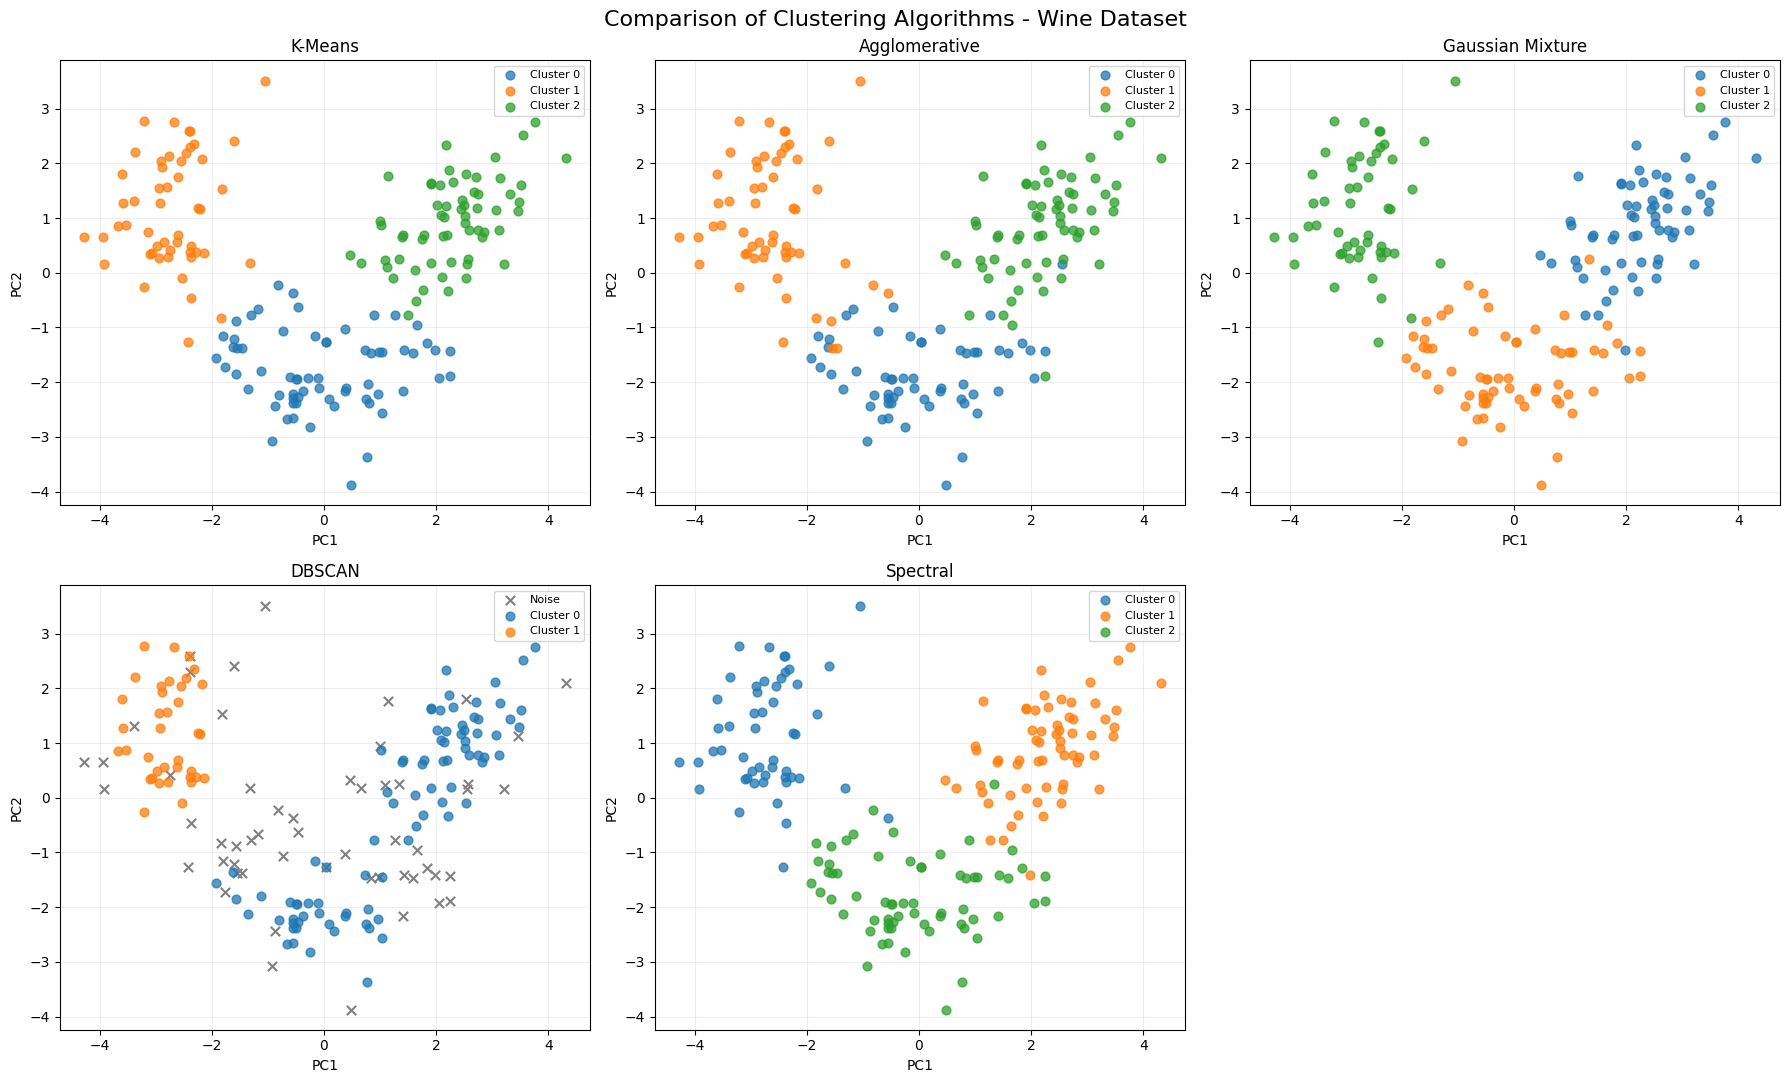

In [20]:
# Use the same PCA projection for every model
pca = PCA(n_components=2)
X_pca = pca.fit_transform(X_scaled)

fig, axes = plt.subplots(
    2, 3,
    figsize=(18, 11)
)

axes = axes.flatten()

for ax, (name, labels) in zip(
    axes, cluster_predictions.items()
):

    unique_labels = np.unique(labels)

    for cluster_id in unique_labels:

        mask = labels == cluster_id

        # Draw noise observations separately
        if cluster_id == -1:
            ax.scatter(
                X_pca[mask, 0],
                X_pca[mask, 1],
                c="gray",
                marker="x",
                s=45,
                label="Noise"
            )
        else:
            ax.scatter(
                X_pca[mask, 0],
                X_pca[mask, 1],
                s=40,
                alpha=0.75,
                label=f"Cluster {cluster_id}"
            )

    ax.set_title(name)
    ax.set_xlabel("PC1")
    ax.set_ylabel("PC2")
    ax.legend(fontsize=8)
    ax.grid(alpha=0.2)

# Hide unused subplot
for ax in axes[len(cluster_predictions):]:
    ax.axis("off")

plt.suptitle(
    "Comparison of Clustering Algorithms - Wine Dataset",
    fontsize=16
)

plt.tight_layout()
plt.show()

In [21]:
# Rank models by Silhouette Score
ranking_df = (
    comparison_df
    .sort_values(
        by="Silhouette",
        ascending=False,
        na_position="last"
    )
    .reset_index(drop=True)
)

print(
    ranking_df[
        [
            "Algorithm",
            "Clusters",
            "Noise",
            "Coverage",
            "Silhouette",
            "DBI",
            "CH"
        ]
    ].round(3).to_string(index=False)
)

       Algorithm  Clusters  Noise  Coverage  Silhouette   DBI     CH
          DBSCAN         2     55     0.691       0.348 1.124 68.391
         K-Means         3      0     1.000       0.285 1.389 70.940
Gaussian Mixture         3      0     1.000       0.284 1.394 70.688
        Spectral         3      0     1.000       0.283 1.391 70.041
   Agglomerative         3      0     1.000       0.277 1.419 67.647


## DBSCAN Hyperparameter Tuning

In [22]:
eps_values = np.arange(1.5, 4.1, 0.1)
min_samples_values = [3, 5, 7, 10]

dbscan_results = []

for eps in eps_values:
    for min_samples in min_samples_values:

        model = DBSCAN(
            eps=float(eps),
            min_samples=min_samples
        )

        labels = model.fit_predict(X_scaled)

        valid_mask = labels != -1
        valid_labels = labels[valid_mask]

        n_clusters = len(np.unique(valid_labels))
        n_noise = np.sum(~valid_mask)
        coverage = valid_mask.mean()

        if 2 <= n_clusters < valid_mask.sum():
            silhouette = silhouette_score(
                X_scaled[valid_mask],
                valid_labels
            )
        else:
            silhouette = np.nan

        dbscan_results.append({
            "eps": round(float(eps), 2),
            "min_samples": min_samples,
            "n_clusters": n_clusters,
            "n_noise": n_noise,
            "coverage": coverage,
            "silhouette": silhouette
        })

dbscan_tuning_df = pd.DataFrame(dbscan_results)

# Show configurations with meaningful coverage
valid_results = dbscan_tuning_df[
    (dbscan_tuning_df["coverage"] >= 0.90) &
    (dbscan_tuning_df["n_clusters"] >= 2) &
    (dbscan_tuning_df["silhouette"].notna())
]

print("Top DBSCAN configurations (Coverage >= 90%):")

print(
    valid_results.sort_values(
        "silhouette",
        ascending=False
    ).head(10).round(3).to_string(index=False)
)

print("\nNumber of valid configurations:", len(valid_results))

Top DBSCAN configurations (Coverage >= 90%):
 eps  min_samples  n_clusters  n_noise  coverage  silhouette
 3.0            3           2        7     0.961       0.239
 3.1            3           2        5     0.972       0.237
 3.2            3           2        5     0.972       0.237
 3.3            3           2        5     0.972       0.237
 3.4            3           2        4     0.978       0.234
 3.5            3           2        3     0.983       0.231
 3.6            3           2        3     0.983       0.231
 3.7            3           2        2     0.989       0.228
 3.8            3           2        2     0.989       0.228
 3.9            3           2        1     0.994       0.226

Number of valid configurations: 11


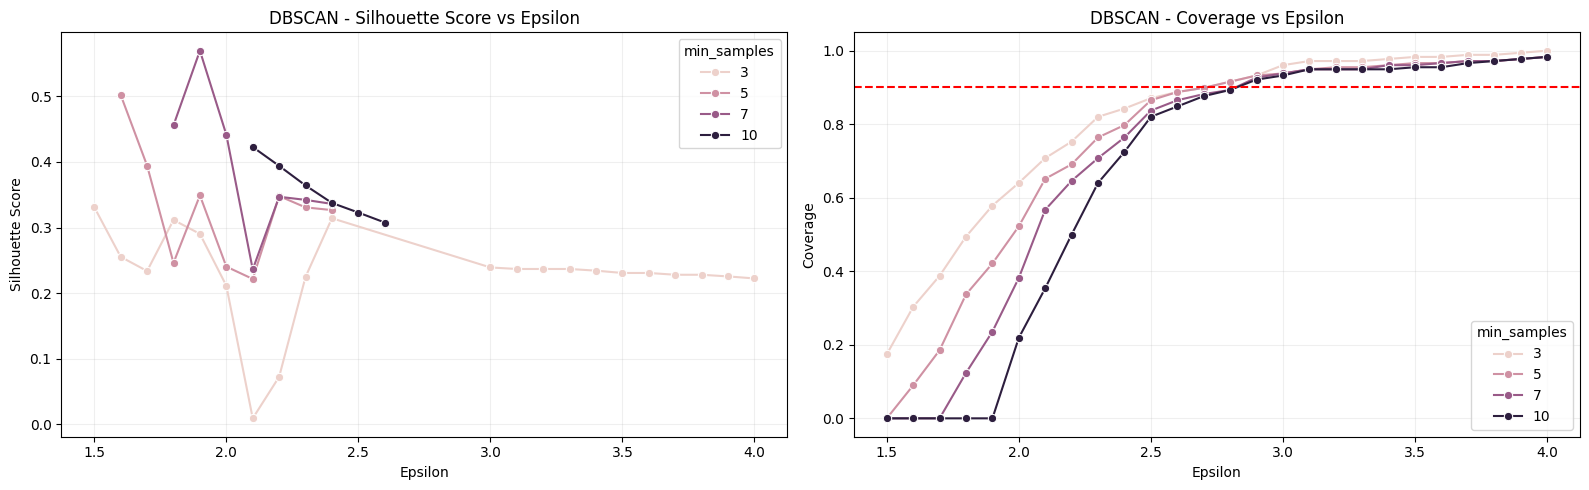

In [24]:
import seaborn as sns

fig, axes = plt.subplots(1, 2, figsize=(16, 5))

# Silhouette Score
sns.lineplot(
    data=dbscan_tuning_df,
    x="eps",
    y="silhouette",
    hue="min_samples",
    marker="o",
    ax=axes[0]
)

axes[0].set_title("DBSCAN - Silhouette Score vs Epsilon")
axes[0].set_xlabel("Epsilon")
axes[0].set_ylabel("Silhouette Score")
axes[0].grid(alpha=0.2)

# Coverage
sns.lineplot(
    data=dbscan_tuning_df,
    x="eps",
    y="coverage",
    hue="min_samples",
    marker="o",
    ax=axes[1]
)

axes[1].axhline(
    y=0.90,
    color="red",
    linestyle="--",
    label="90% Coverage"
)

axes[1].set_title("DBSCAN - Coverage vs Epsilon")
axes[1].set_xlabel("Epsilon")
axes[1].set_ylabel("Coverage")
axes[1].grid(alpha=0.2)

plt.tight_layout()
plt.show()

## HDBSCAN Hyperparameter Tuning

In [25]:
from sklearn.cluster import HDBSCAN
from sklearn.metrics import (
    silhouette_score,
    davies_bouldin_score,
    calinski_harabasz_score
)

# Hyperparameter grid
min_cluster_sizes = [3, 5, 10, 15, 20]
min_samples_values = [3, 5, 10]

hdbscan_results = []
hdbscan_predictions = {}

for min_cluster_size in min_cluster_sizes:
    for min_samples in min_samples_values:

        model = HDBSCAN(
            min_cluster_size=min_cluster_size,
            min_samples=min_samples
        )

        labels = model.fit_predict(X_scaled)

        key = (min_cluster_size, min_samples)
        hdbscan_predictions[key] = labels

        valid_mask = labels != -1
        valid_labels = labels[valid_mask]

        n_clusters = len(np.unique(valid_labels))
        n_noise = np.sum(~valid_mask)
        coverage = valid_mask.mean()

        if 2 <= n_clusters < valid_mask.sum():

            silhouette = silhouette_score(
                X_scaled[valid_mask],
                valid_labels
            )

            dbi = davies_bouldin_score(
                X_scaled[valid_mask],
                valid_labels
            )

            ch = calinski_harabasz_score(
                X_scaled[valid_mask],
                valid_labels
            )

        else:
            silhouette = np.nan
            dbi = np.nan
            ch = np.nan

        hdbscan_results.append({
            "min_cluster_size": min_cluster_size,
            "min_samples": min_samples,
            "n_clusters": n_clusters,
            "n_noise": n_noise,
            "coverage": coverage,
            "silhouette": silhouette,
            "DBI": dbi,
            "CH": ch
        })

hdbscan_df = pd.DataFrame(hdbscan_results)

print(
    hdbscan_df
    .sort_values(
        "silhouette",
        ascending=False,
        na_position="last"
    )
    .round(3)
    .to_string(index=False)
)

 min_cluster_size  min_samples  n_clusters  n_noise  coverage  silhouette   DBI     CH
                3           10           2       75     0.579       0.363 1.046 59.329
                5           10           2       75     0.579       0.363 1.046 59.329
               10           10           2       75     0.579       0.363 1.046 59.329
               15           10           2       75     0.579       0.363 1.046 59.329
               20           10           2       75     0.579       0.363 1.046 59.329
                5            5           2       58     0.674       0.352 1.093 66.912
                3            5           2       58     0.674       0.352 1.093 66.912
               20            5           2       58     0.674       0.352 1.093 66.912
               15            5           2       58     0.674       0.352 1.093 66.912
               10            5           2       58     0.674       0.352 1.093 66.912
                5            3           2 

In [26]:
# Inspect representative HDBSCAN configurations
configs = [
    (5, 3),
    (5, 5),
    (5, 10),
    (3, 3)
]

for min_cluster_size, min_samples in configs:

    model = HDBSCAN(
        min_cluster_size=min_cluster_size,
        min_samples=min_samples
    )

    labels = model.fit_predict(X_scaled)

    print(
        f"\nmin_cluster_size={min_cluster_size}, "
        f"min_samples={min_samples}"
    )

    print(
        pd.Series(labels)
        .value_counts()
        .sort_index()
        .rename_axis("Cluster")
        .to_string()
    )


min_cluster_size=5, min_samples=3
Cluster
-1    39
 0    96
 1    43

min_cluster_size=5, min_samples=5
Cluster
-1    58
 0    86
 1    34

min_cluster_size=5, min_samples=10
Cluster
-1    75
 0    75
 1    28

min_cluster_size=3, min_samples=3
Cluster
-1      3
 0    172
 1      3


### Results & Interpretation - HDBSCAN Cluster Size Analysis

The HDBSCAN cluster size analysis reveals substantial sensitivity to the `min_samples` parameter.

With `min_cluster_size=5`, increasing `min_samples` from 3 to 10 increased the number of noise observations from 39 to 75, while the Silhouette Score increased from 0.323 to 0.363.

This indicates a trade-off between cluster coverage and separation quality.

The configuration with `min_cluster_size=3` and `min_samples=3` produced a highly imbalanced clustering structure, assigning 172 observations to one cluster, 3 observations to another, and 3 observations to noise.

Although technically valid, this configuration provides limited segmentation value because nearly all observations belong to a single cluster.

Among the evaluated HDBSCAN configurations, `min_cluster_size=5` and `min_samples=3` offers a reasonable candidate for further investigation, with 78.1% coverage and a Silhouette Score of 0.323.

Overall, K-Means remains a suitable baseline for complete segmentation of the Wine dataset, whereas HDBSCAN offers an alternative when identifying dense groups and low-density observations is an explicit objective.

## ARI & NMI Comparision

In [27]:
from sklearn.metrics import (
    adjusted_rand_score,
    normalized_mutual_info_score
)

# Compare only models that assigned every observation
model_names = [
    "K-Means",
    "Agglomerative",
    "Gaussian Mixture",
    "Spectral"
]

ari_matrix = pd.DataFrame(
    index=model_names,
    columns=model_names,
    dtype=float
)

nmi_matrix = pd.DataFrame(
    index=model_names,
    columns=model_names,
    dtype=float
)

# Pairwise comparison
for model_a in model_names:
    for model_b in model_names:

        labels_a = cluster_predictions[model_a]
        labels_b = cluster_predictions[model_b]

        ari_matrix.loc[model_a, model_b] = (
            adjusted_rand_score(labels_a, labels_b)
        )

        nmi_matrix.loc[model_a, model_b] = (
            normalized_mutual_info_score(
                labels_a,
                labels_b
            )
        )

print("Adjusted Rand Index (ARI):")
print(ari_matrix.round(3))

print("\nNormalized Mutual Information (NMI):")
print(nmi_matrix.round(3))

Adjusted Rand Index (ARI):
                  K-Means  Agglomerative  Gaussian Mixture  Spectral
K-Means             1.000          0.853             0.947     0.915
Agglomerative       0.853          1.000             0.806     0.806
Gaussian Mixture    0.947          0.806             1.000     0.968
Spectral            0.915          0.806             0.968     1.000

Normalized Mutual Information (NMI):
                  K-Means  Agglomerative  Gaussian Mixture  Spectral
K-Means             1.000          0.824             0.928     0.876
Agglomerative       0.824          1.000             0.775     0.775
Gaussian Mixture    0.928          0.775             1.000     0.948
Spectral            0.876          0.775             0.948     1.000


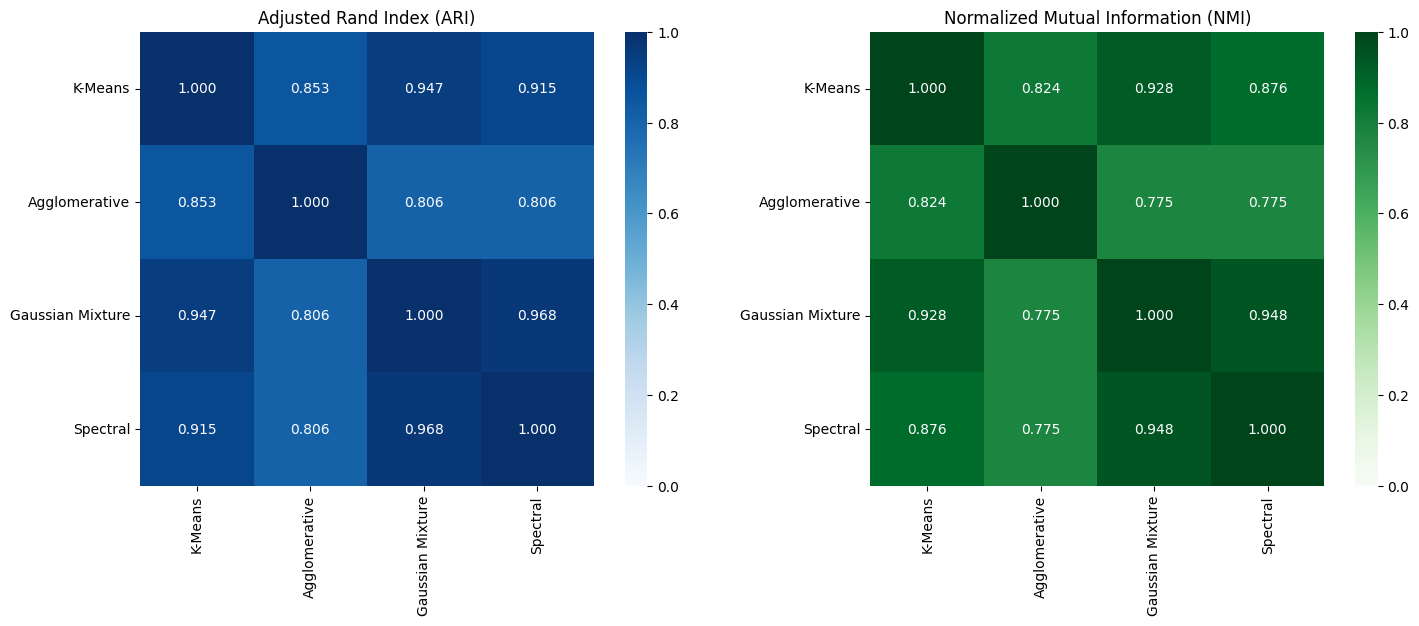

In [28]:
fig, axes = plt.subplots(
    1, 2,
    figsize=(15, 6)
)

sns.heatmap(
    ari_matrix,
    annot=True,
    fmt=".3f",
    cmap="Blues",
    vmin=0,
    vmax=1,
    square=True,
    ax=axes[0]
)

axes[0].set_title(
    "Adjusted Rand Index (ARI)"
)

sns.heatmap(
    nmi_matrix,
    annot=True,
    fmt=".3f",
    cmap="Greens",
    vmin=0,
    vmax=1,
    square=True,
    ax=axes[1]
)

axes[1].set_title(
    "Normalized Mutual Information (NMI)"
)

plt.tight_layout()
plt.show()

In [30]:
from itertools import combinations

pairwise_results = []

for model_a, model_b in combinations(model_names, 2):

    pairwise_results.append({
        "Model A": model_a,
        "Model B": model_b,
        "ARI": adjusted_rand_score(
            cluster_predictions[model_a],
            cluster_predictions[model_b]
        ),
        "NMI": normalized_mutual_info_score(
            cluster_predictions[model_a],
            cluster_predictions[model_b]
        )
    })

pairwise_df = pd.DataFrame(pairwise_results)

pairwise_df = pairwise_df.sort_values(
    "ARI",
    ascending=False
).reset_index(drop=True)

print(pairwise_df.round(3).to_string(index=False))

         Model A          Model B   ARI   NMI
Gaussian Mixture         Spectral 0.968 0.948
         K-Means Gaussian Mixture 0.947 0.928
         K-Means         Spectral 0.915 0.876
         K-Means    Agglomerative 0.853 0.824
   Agglomerative Gaussian Mixture 0.806 0.775
   Agglomerative         Spectral 0.806 0.775


### Results & Interpretation - ARI and NMI Agreement Analysis

The pairwise clustering agreement analysis revealed substantial consistency across K-Means, Gaussian Mixture, Spectral Clustering, and Agglomerative Clustering.

The highest agreement was observed between Gaussian Mixture and Spectral Clustering, with an Adjusted Rand Index (ARI) of 0.968 and Normalized Mutual Information (NMI) of 0.948.

K-Means also demonstrated strong agreement with Gaussian Mixture (ARI = 0.947) and Spectral Clustering (ARI = 0.915).

Agglomerative Clustering produced slightly different assignments, although its agreement with the other algorithms remained relatively high.

These results suggest that the three-cluster partition is reasonably consistent across different clustering approaches.

However, all four algorithms were configured to produce three clusters. Therefore, high agreement does not independently establish that three is the optimal number of clusters.

Further investigation of clustering stability under different random initializations and data perturbations is necessary to assess the robustness of the identified structure.

## Cluster Stability Analysis

In [31]:
from sklearn.cluster import KMeans
from sklearn.metrics import adjusted_rand_score

# Train K-Means with different random seeds
random_seeds = range(30)

predictions = []

for seed in random_seeds:

    model = KMeans(
        n_clusters=3,
        random_state=seed,
        n_init=20
    )

    labels = model.fit_predict(X_scaled)

    predictions.append(labels)

# Pairwise ARI between different runs
stability_scores = []

for i in range(len(predictions)):
    for j in range(i + 1, len(predictions)):

        score = adjusted_rand_score(
            predictions[i],
            predictions[j]
        )

        stability_scores.append(score)

stability_scores = np.array(stability_scores)

print("Number of comparisons:", len(stability_scores))
print("Mean ARI:", round(stability_scores.mean(), 4))
print("Std ARI:", round(stability_scores.std(), 4))
print("Min ARI:", round(stability_scores.min(), 4))
print("Max ARI:", round(stability_scores.max(), 4))

Number of comparisons: 435
Mean ARI: 1.0
Std ARI: 0.0
Min ARI: 1.0
Max ARI: 1.0


## Data Perturbation Stability Analysis

Mean ARI: 0.9809
Std ARI: 0.0234
Min ARI: 0.9143
Max ARI: 1.0
5th percentile: 0.935


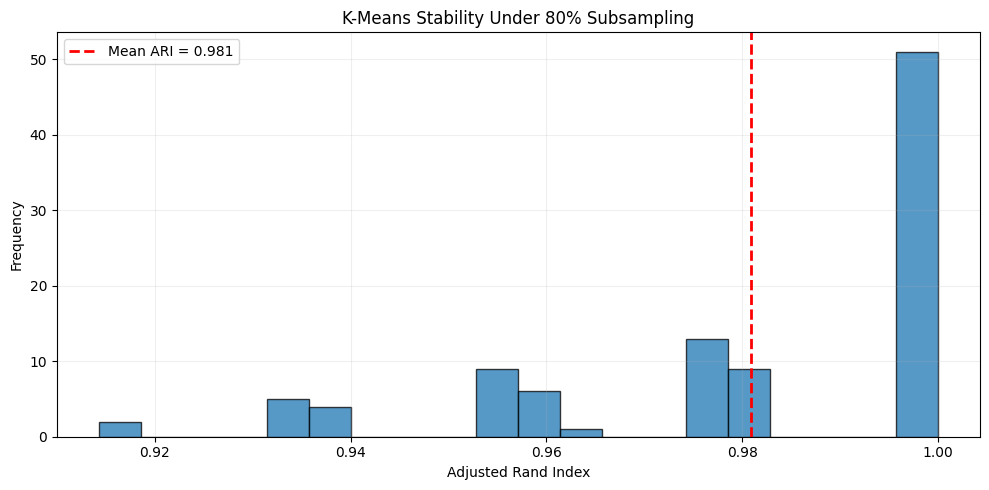

In [32]:
# Experiment settings
n_iterations = 100
train_fraction = 0.80

rng = np.random.default_rng(42)

# Use original features to refit preprocessing
X_array = X.to_numpy()
n_samples = len(X_array)

# Reference assignments from the full-data model
reference_labels = final_model.labels_

stability_results = []

for iteration in range(n_iterations):

    # Randomly select 80% of observations
    sample_indices = rng.choice(
        n_samples,
        size=int(n_samples * train_fraction),
        replace=False
    )

    # Fit preprocessing only on selected observations
    X_subset = X_array[sample_indices]

    subset_scaler = StandardScaler()
    X_subset_scaled = subset_scaler.fit_transform(
        X_subset
    )

    # Train K-Means on the subset
    subset_model = KMeans(
        n_clusters=3,
        random_state=42,
        n_init=20
    )

    subset_labels = subset_model.fit_predict(
        X_subset_scaled
    )

    # Compare assignments for the same observations
    reference_subset_labels = reference_labels[
        sample_indices
    ]

    ari = adjusted_rand_score(
        reference_subset_labels,
        subset_labels
    )

    stability_results.append(ari)

stability_results = np.array(stability_results)

print("Mean ARI:", round(stability_results.mean(), 4))
print("Std ARI:", round(stability_results.std(), 4))
print("Min ARI:", round(stability_results.min(), 4))
print("Max ARI:", round(stability_results.max(), 4))
print("5th percentile:",round(np.percentile(stability_results, 5), 4))

# Plot stability distribution
plt.figure(figsize=(10, 5))

plt.hist(
    stability_results,
    bins=20,
    edgecolor="black",
    alpha=0.75
)

plt.axvline(
    stability_results.mean(),
    color="red",
    linestyle="--",
    linewidth=2,
    label=f"Mean ARI = {stability_results.mean():.3f}"
)

plt.xlabel("Adjusted Rand Index")
plt.ylabel("Frequency")
plt.title("K-Means Stability Under 80% Subsampling")
plt.legend()
plt.grid(alpha=0.2)
plt.tight_layout()
plt.show()

### Results & Interpretation - K-Means Subsampling Stability

The robustness of K-Means clustering was evaluated using 100 random subsampling experiments, each retaining 80% of the original observations.

For each iteration, feature standardization and K-Means clustering were fitted independently on the selected subset. The resulting assignments were compared against the corresponding observations from the full-data reference model using the Adjusted Rand Index (ARI).

**Results:**

- Mean ARI: 0.9809
- Standard Deviation: 0.0234
- Minimum ARI: 0.9143
- Maximum ARI: 1.0000
- 5th Percentile: 0.9350

The results indicate high clustering stability under moderate changes in the training dataset.

Most subsampling experiments produced partitions that closely agreed with the full-data reference clustering solution. Even the lowest observed ARI remained above 0.91.

Combined with the initialization stability results (Mean ARI = 1.0000), these findings suggest that the three-cluster K-Means solution is robust to random initialization and relatively insensitive to the removal of 20% of the observations.

However, clustering stability should not be interpreted as evidence of perfect cluster separation or correspondence with the underlying true classes. The

# Cluster Profiling

In [33]:
# Create a copy of the original dataset
clustered_df = X.copy()

# Add K-Means cluster assignments
clustered_df["Cluster"] = cluster_labels

# Cluster sizes
cluster_sizes = (
    clustered_df["Cluster"]
    .value_counts()
    .sort_index()
)

print("Cluster Sizes:")
print(cluster_sizes)

# Descriptive statistics for each cluster
cluster_stats = clustered_df.groupby("Cluster").agg(
    ["mean", "median", "std", "min", "max"]
)

# Display mean values for all features
cluster_means = (
    clustered_df
    .groupby("Cluster")
    .mean()
)

print("\nCluster Feature Means:")
print(cluster_means.round(3).to_string())

Cluster Sizes:
Cluster
0    65
1    51
2    62
Name: count, dtype: int64

Cluster Feature Means:
         alcohol  malic_acid    ash  alcalinity_of_ash  magnesium  total_phenols  flavanoids  nonflavanoid_phenols  proanthocyanins  color_intensity    hue  od280/od315_of_diluted_wines   proline
Cluster                                                                                                                                                                                            
0         12.251       1.897  2.231             20.063     92.738          2.248       2.050                 0.358            1.624            2.973  1.063                         2.803   510.169
1         13.134       3.307  2.418             21.241     98.667          1.684       0.819                 0.452            1.146            7.235  0.692                         1.697   619.059
2         13.677       1.998  2.466             17.463    107.968          2.848       3.003                 0.292     

## Standardized Cluster Profile Heatmap

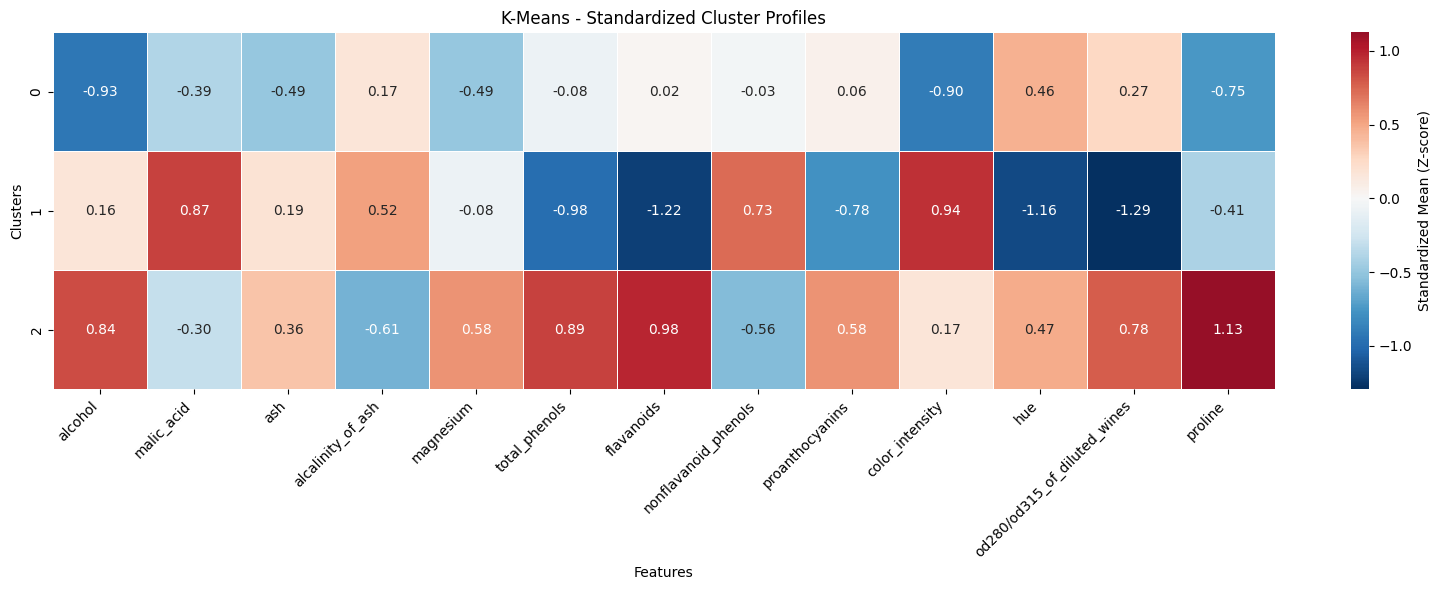

In [34]:
# Standardize cluster-level feature means
cluster_profile_scaled = (
    (cluster_means - X.mean()) /
    X.std(ddof=0)
)

plt.figure(figsize=(16, 6))

sns.heatmap(
    cluster_profile_scaled,
    annot=True,
    fmt=".2f",
    cmap="RdBu_r",
    center=0,
    linewidths=0.5,
    cbar_kws={"label": "Standardized Mean (Z-score)"}
)

plt.title("K-Means - Standardized Cluster Profiles")
plt.xlabel("Features")
plt.ylabel("Clusters")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

## Feature Distribution - Boxplots

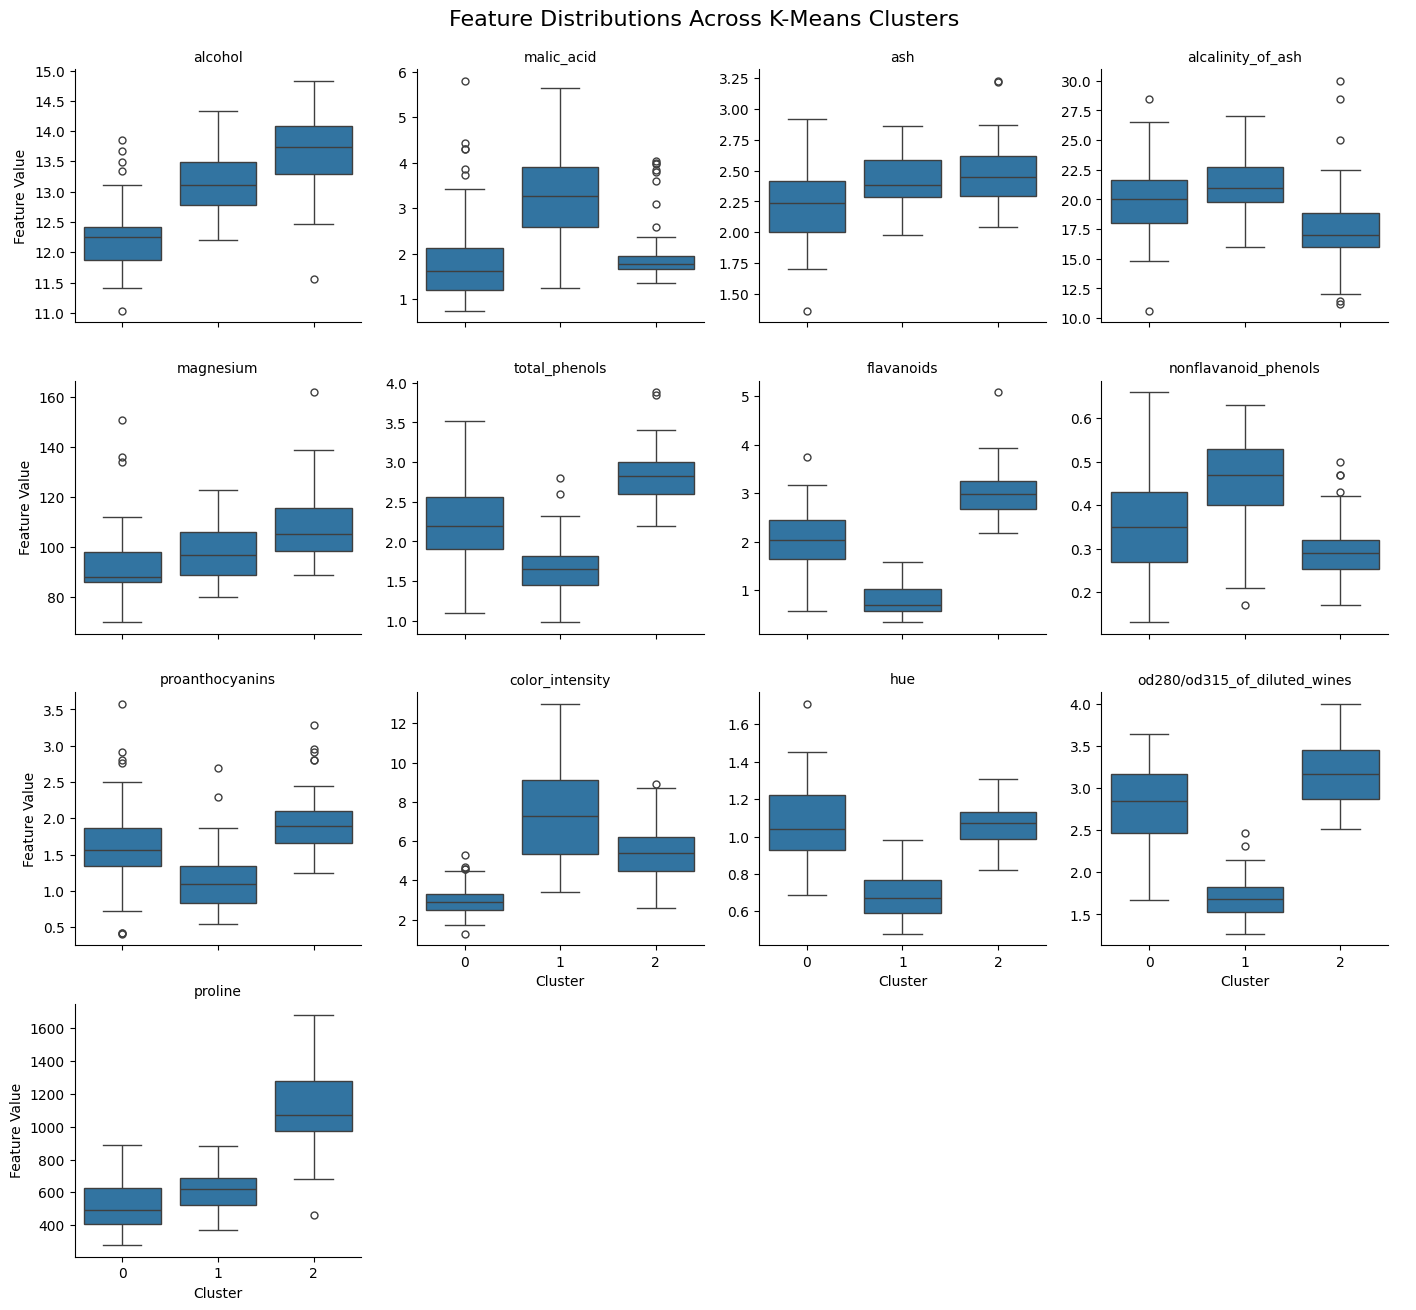

In [35]:
# Convert dataset to long format
plot_df = clustered_df.melt(
    id_vars="Cluster",
    var_name="Feature",
    value_name="Value"
)

# Create separate boxplots for every feature
g = sns.catplot(
    data=plot_df,
    x="Cluster",
    y="Value",
    col="Feature",
    col_wrap=4,
    kind="box",
    sharey=False,
    height=3.2,
    aspect=1.1
)

g.set_titles("{col_name}")
g.set_axis_labels("Cluster", "Feature Value")

g.figure.suptitle(
    "Feature Distributions Across K-Means Clusters",
    fontsize=16,
    y=1.02
)

plt.show()

### Results & Interpretation - Cluster Profiling and Interpretation

The standardized cluster profile heatmap and feature distribution boxplots reveal distinct chemical characteristics across the three K-Means clusters.

**Cluster 0 — Low-Alcohol & Low-Intensity Wines**

This cluster is characterized by below-average alcohol concentration (Z = -0.93), color intensity (Z = -0.90), and proline (Z = -0.75). Flavanoid and total phenol concentrations remain relatively close to the overall dataset averages.

**Cluster 1 — High-Intensity & Low-Phenolic Wines**

This cluster exhibits above-average color intensity (Z = 0.94) and malic acid (Z = 0.87), combined with substantially lower flavanoid (Z = -1.22), total phenol (Z = -0.98), hue (Z = -1.16), and OD280/OD315 (Z = -1.29) values.

These characteristics distinguish Cluster 1 from the other groups.

**Cluster 2 — High-Alcohol & Phenolic-Rich Wines**

This cluster is characterized by elevated proline (Z = 1.13), flavanoids (Z = 0.98), total phenols (Z = 0.89), alcohol (Z = 0.84), and OD280/OD315 (Z = 0.78).

The boxplots support these findings by showing differences in medians and feature distributions across clusters.

Overall, cluster profiling indicates that the identified groups are distinguishable by combinations of chemical properties. Descriptive cluster names were assigned based on their relative feature characteristics rather than predefined wine classifications.

## Cluster Naming

In [36]:
# Define cluster names based on feature profiles
cluster_names = {
    0: "Low-Alcohol & Low-Intensity Wines",
    1: "High-Intensity & Low-Phenolic Wines",
    2: "High-Alcohol & Phenolic-Rich Wines"
}

# Assign descriptive cluster names
clustered_df["Cluster_Name"] = (
    clustered_df["Cluster"].map(cluster_names)
)

# Display cluster distribution
cluster_distribution = (
    clustered_df["Cluster_Name"]
    .value_counts()
    .rename_axis("Cluster Name")
    .reset_index(name="Observations")
)

cluster_distribution["Percentage"] = (
    cluster_distribution["Observations"]
    / len(clustered_df) * 100
).round(2)

print(cluster_distribution.to_string(index=False))

                       Cluster Name  Observations  Percentage
  Low-Alcohol & Low-Intensity Wines            65       36.52
 High-Alcohol & Phenolic-Rich Wines            62       34.83
High-Intensity & Low-Phenolic Wines            51       28.65


## Model Pipeline

In [38]:
import joblib
import sklearn

from sklearn.pipeline import Pipeline

# Create a pipeline using already fitted objects
clustering_pipeline = Pipeline([
    ("scaler", scaler),
    ("kmeans", final_model)
])

# Store the pipeline and metadata
model_artifact = {
    "pipeline": clustering_pipeline,
    "feature_names": X.columns.tolist(),
    "cluster_names": cluster_names,
    "n_clusters": final_model.n_clusters,
    "sklearn_version": sklearn.__version__
}

# Save artifact
joblib.dump(
    model_artifact,
    "wine_clustering_pipeline.joblib"
)

print("Model saved successfully!")
print("Clusters:", model_artifact["n_clusters"])
print("Features:", len(model_artifact["feature_names"]))


Model saved successfully!
Clusters: 3
Features: 13


## Model Load

In [39]:
# Load saved clustering artifact
loaded_artifact = joblib.load(
    "wine_clustering_pipeline.joblib"
)

loaded_pipeline = loaded_artifact["pipeline"]
feature_names = loaded_artifact["feature_names"]
loaded_cluster_names = loaded_artifact["cluster_names"]

print("Model loaded successfully!")
print("Number of clusters:", loaded_pipeline.named_steps["kmeans"].n_clusters)
print("Required features:", len(feature_names))

Model loaded successfully!
Number of clusters: 3
Required features: 13


## Prediction for new observation

In [40]:
# New wine observation
new_wine = pd.DataFrame([{
    "alcohol": 13.8,
    "malic_acid": 1.9,
    "ash": 2.5,
    "alcalinity_of_ash": 16.5,
    "magnesium": 105.0,
    "total_phenols": 2.85,
    "flavanoids": 3.0,
    "nonflavanoid_phenols": 0.30,
    "proanthocyanins": 1.90,
    "color_intensity": 5.6,
    "hue": 1.05,
    "od280/od315_of_diluted_wines": 3.1,
    "proline": 1100.0
}])

# Preserve training feature order
new_wine = new_wine[feature_names]

# Predict using loaded pipeline
predicted_cluster = int(
    loaded_pipeline.predict(new_wine)[0]
)

predicted_name = loaded_cluster_names[
    predicted_cluster
]

print("Predicted Cluster:", predicted_cluster)
print("Cluster Name:", predicted_name)

Predicted Cluster: 2
Cluster Name: High-Alcohol & Phenolic-Rich Wines


In [41]:
# Extract fitted scaler and K-Means model
loaded_scaler = loaded_pipeline.named_steps["scaler"]
loaded_kmeans = loaded_pipeline.named_steps["kmeans"]

# Transform new observation
new_wine_scaled = loaded_scaler.transform(new_wine)

# Compute distances to all cluster centroids
distances = loaded_kmeans.transform(new_wine_scaled)[0]

distance_df = pd.DataFrame({
    "Cluster": range(len(distances)),
    "Cluster Name": [
        loaded_cluster_names[i]
        for i in range(len(distances))
    ],
    "Distance": distances
})

distance_df = distance_df.sort_values(
    "Distance"
).reset_index(drop=True)

print(distance_df.round(4).to_string(index=False))

 Cluster                        Cluster Name  Distance
       2  High-Alcohol & Phenolic-Rich Wines     0.442
       0   Low-Alcohol & Low-Intensity Wines     3.715
       1 High-Intensity & Low-Phenolic Wines     5.036


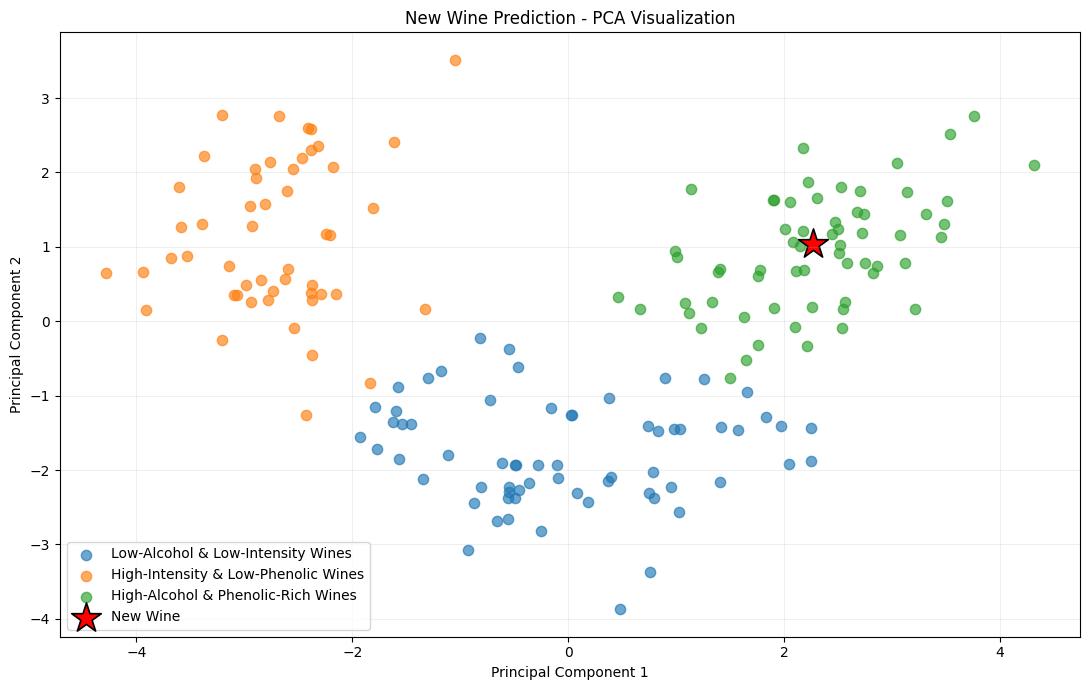

In [42]:
# Project new observation into existing PCA space
new_wine_pca = pca.transform(new_wine_scaled)

# Plot existing clusters
plt.figure(figsize=(11, 7))

for cluster_id in np.unique(cluster_labels):

    mask = cluster_labels == cluster_id

    plt.scatter(
        X_pca[mask, 0],
        X_pca[mask, 1],
        s=55,
        alpha=0.65,
        label=cluster_names[int(cluster_id)]
    )

# Plot new observation
plt.scatter(
    new_wine_pca[:, 0],
    new_wine_pca[:, 1],
    c="red",
    marker="*",
    s=500,
    edgecolors="black",
    linewidths=1.2,
    label="New Wine"
)

plt.xlabel("Principal Component 1")
plt.ylabel("Principal Component 2")
plt.title("New Wine Prediction - PCA Visualization")

plt.legend()
plt.grid(alpha=0.2)
plt.tight_layout()
plt.show()

### Results & Interpretation - Model Persistence and Cluster Inference

The trained K-Means clustering model was packaged with its fitted StandardScaler using a scikit-learn Pipeline and serialized with Joblib.

The saved artifact also includes the original feature names, cluster descriptions, and model metadata.

After reloading the artifact, a new wine observation can be assigned to one of the three previously identified clusters without retraining the model.

The Pipeline ensures that new observations undergo the same standardization transformation used during model training.

Cluster assignment is determined by the Euclidean distance between the standardized observation and the learned cluster centroids.

Distances to all centroids can also be inspected to understand the relative proximity of the observation to each cluster. However, these distances should not be interpreted as calibrated membership probabilities.

Finally, the new observation can be projected into the previously fitted PCA space to visualize its location relative to the existing clusters.

training → evaluation → stability → cluster profiling → naming → model persistence → inference